In [1]:
import os, glob, random, warnings
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import (Dense, GlobalAveragePooling2D, Dropout, Input, Conv2D,
                                     BatchNormalization, Activation, MaxPooling2D,
                                     Conv2DTranspose, concatenate)
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---------------- Classifier config (same as your original) ----------------
IMG_SIZE   = (320, 320)          # (width, height) used by cv2 and the generators
BATCH_SIZE = 16
BASE_PATH  = '/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/'

# ---------------- Segmentation config ----------------
SEG_SIZE       = 256             # U-Net input resolution
SEG_ROOT       = '/kaggle/input' # searched recursively for the mask dataset
MIN_LUNG_FRAC  = 0.05            # if predicted lungs < 5% of the image -> fall back to the full image
SEG_OUT_DIR    = '/kaggle/working/seg_images'
os.makedirs(SEG_OUT_DIR, exist_ok=True)

# ---------------- Uncertainty config ----------------
T_MC           = 30              # stochastic passes for test-set analysis
T_INFER        = 50              # stochastic passes for single-image inference
ENTROPY_THRESH = 0.50            # normalised predictive entropy (0..1) above which a case is flagged

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
def seg_preprocess(gray_uint8):
    """Shared by U-Net training AND inference: resize -> CLAHE -> [0,1]."""
    g = cv2.resize(gray_uint8, (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_AREA)
    g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
    return g.astype('float32') / 255.0

# --- discover image/mask pairs anywhere under /kaggle/input (skipping the pneumonia dataset) ---
IMG_EXT = ('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp')
images, masks = {}, {}
for root, _, files in os.walk(SEG_ROOT):
    if 'chest_xray' in root.lower() or 'paultimothymooney' in root.lower():
        continue
    parts = root.lower().split(os.sep)
    in_mask_folder = any(p in ('mask', 'masks') for p in parts)   # exact folder name, not a substring
    for f in files:
        if not f.lower().endswith(IMG_EXT):
            continue
        stem = os.path.splitext(f)[0]
        full = os.path.join(root, f)
        if in_mask_folder or stem.endswith('_mask'):
            masks[stem.replace('_mask', '')] = full
        else:
            images[stem] = full

pair_keys = sorted(set(images) & set(masks))
print(f"images found: {len(images)} | masks found: {len(masks)} | matched pairs: {len(pair_keys)}")
if len(pair_keys) <= 50:
    print("Example image paths:", list(images.values())[:3])
    print("Example mask paths :", list(masks.values())[:3])
assert len(pair_keys) > 50, ("Lung-mask dataset not found or names don't match. "
                             "Attach 'Chest X-ray Masks and Labels' (nikhilpandey360) and run the directory check.")

X, Y = [], []
for k in tqdm(pair_keys, desc="Loading U-Net data"):
    img  = cv2.imread(images[k], cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(masks[k],  cv2.IMREAD_GRAYSCALE)
    if img is None or mask is None:
        continue
    X.append(seg_preprocess(img))
    m = cv2.resize(mask, (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_NEAREST)
    Y.append((m > 127).astype('float32'))

X = np.array(X, dtype='float32')[..., None]
Y = np.array(Y, dtype='float32')[..., None]
Xtr, Xva, Ytr, Yva = train_test_split(X, Y, test_size=0.15, random_state=SEED)
print("U-Net train:", Xtr.shape, "| val:", Xva.shape)

images found: 800 | masks found: 704 | matched pairs: 704


Loading U-Net data:   0%|          | 0/704 [00:00<?, ?it/s]

U-Net train: (598, 256, 256, 1) | val: (106, 256, 256, 1)


In [3]:
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true = tf.cast(y_true, tf.float32)
    b = tf.shape(y_true)[0]
    yt = tf.reshape(y_true, [b, -1])
    yp = tf.reshape(y_pred, [b, -1])
    inter = tf.reduce_sum(yt * yp, axis=1)
    return tf.reduce_mean((2. * inter + smooth) /
                          (tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1) + smooth))

def bce_dice_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + (1.0 - dice_coef(y_true, y_pred))

def conv_block(x, f):
    for _ in range(2):
        x = Conv2D(f, 3, padding='same', use_bias=False)(x)
        x = BatchNormalization()(x)
        x = Activation('relu')(x)
    return x

def build_unet(input_shape=(SEG_SIZE, SEG_SIZE, 1), base=32):
    inp = Input(input_shape)
    c1 = conv_block(inp, base);        p1 = MaxPooling2D()(c1)
    c2 = conv_block(p1, base * 2);     p2 = MaxPooling2D()(c2)
    c3 = conv_block(p2, base * 4);     p3 = MaxPooling2D()(c3)
    c4 = conv_block(p3, base * 8);     p4 = MaxPooling2D()(c4)
    bn = conv_block(p4, base * 16)

    u4 = Conv2DTranspose(base * 8, 2, strides=2, padding='same')(bn)
    c5 = conv_block(concatenate([u4, c4]), base * 8)
    u3 = Conv2DTranspose(base * 4, 2, strides=2, padding='same')(c5)
    c6 = conv_block(concatenate([u3, c3]), base * 4)
    u2 = Conv2DTranspose(base * 2, 2, strides=2, padding='same')(c6)
    c7 = conv_block(concatenate([u2, c2]), base * 2)
    u1 = Conv2DTranspose(base, 2, strides=2, padding='same')(c7)
    c8 = conv_block(concatenate([u1, c1]), base)

    out = Conv2D(1, 1, activation='sigmoid')(c8)
    return Model(inp, out, name='unet_lung')

unet = build_unet()
unet.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=bce_dice_loss, metrics=[dice_coef])
print("U-Net parameters:", f"{unet.count_params():,}")

U-Net parameters: 7,768,353


In [4]:
def augment(img, msk):
    both = tf.concat([img, msk], axis=-1)                     # (H, W, 2)
    both = tf.image.random_flip_left_right(both)
    ch = tf.cast(tf.cast(SEG_SIZE, tf.float32) * tf.random.uniform([], 0.85, 1.0), tf.int32)
    both = tf.image.random_crop(both, [ch, ch, 2])            # random zoom-in
    both = tf.image.resize(both, (SEG_SIZE, SEG_SIZE), method='bilinear')
    img, msk = both[..., :1], tf.round(both[..., 1:])
    img = tf.image.random_brightness(img, 0.10)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    return tf.clip_by_value(img, 0., 1.), msk

SEG_BATCH = 8
train_ds = (tf.data.Dataset.from_tensor_slices((Xtr, Ytr))
            .shuffle(len(Xtr), seed=SEED).map(augment, tf.data.AUTOTUNE)
            .batch(SEG_BATCH).prefetch(tf.data.AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((Xva, Yva)).batch(SEG_BATCH).prefetch(tf.data.AUTOTUNE)

unet_ckpt = ModelCheckpoint('/kaggle/working/unet_lung.weights.h5', monitor='val_dice_coef',
                            mode='max', save_best_only=True, save_weights_only=True)
unet_cbs = [unet_ckpt,
            EarlyStopping(monitor='val_dice_coef', mode='max', patience=12, restore_best_weights=True),
            ReduceLROnPlateau(monitor='val_dice_coef', mode='max', factor=0.5, patience=5, min_lr=1e-6)]

unet_hist = unet.fit(train_ds, validation_data=val_ds, epochs=60, callbacks=unet_cbs)
print("Best val Dice:", max(unet_hist.history['val_dice_coef']))

Epoch 1/60


E0000 00:00:1794507351.368103      75 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794507355.422124      75 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794507356.317072      75 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794507357.002873      75 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794507357.682819      75 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000

74/75 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - dice_coef: 0.6890 - loss: 0.6579

E0000 00:00:1794507396.779644      72 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794507399.867361      72 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794507400.492135      72 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794507403.453140      72 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794507404.515417      72 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000

75/75 ━━━━━━━━━━━━━━━━━━━━ 88s 631ms/step - dice_coef: 0.7752 - loss: 0.4475 - val_dice_coef: 0.1814 - val_loss: 1.5692 - learning_rate: 0.0010
Epoch 2/60
75/75 ━━━━━━━━━━━━━━━━━━━━ 16s 216ms/step - dice_coef: 0.8886 - loss: 0.2173 - val_dice_coef: 0.0964 - val_loss: 1.6520 - learning_rate: 0.0010
Epoch 3/60
75/75 ━━━━━━━━━━━━━━━━━━━━ 17s 222ms/step - dice_coef: 0.9196 - loss: 0.1669 - val_dice_coef: 0.0291 - val_loss: 2.0263 - learning_rate: 0.0010
Epoch 4/60
75/75 ━━━━━━━━━━━━━━━━━━━━ 17s 229ms/step - dice_coef: 0.9325 - loss: 0.1461 - val_dice_coef: 0.0257 - val_loss: 2.0644 - learning_rate: 0.0010
Epoch 5/60
75/75 ━━━━━━━━━━━━━━━━━━━━ 18s 242ms/step - dice_coef: 0.9393 - loss: 0.1348 - val_dice_coef: 0.2515 - val_loss: 1.5364 - learning_rate: 0.0010
Epoch 6/60
75/75 ━━━━━━━━━━━━━━━━━━━━ 19s 252ms/step - dice_coef: 0.9431 - loss: 0.1275 - val_dice_coef: 0.7496 - val_loss: 0.6159 - learning_rate: 0.0010
Epoch 7/60
75/75 ━━━━━━━━━━━━━━━━━━━━ 19s 259ms/step - dice_coef: 0.9436 - loss: 

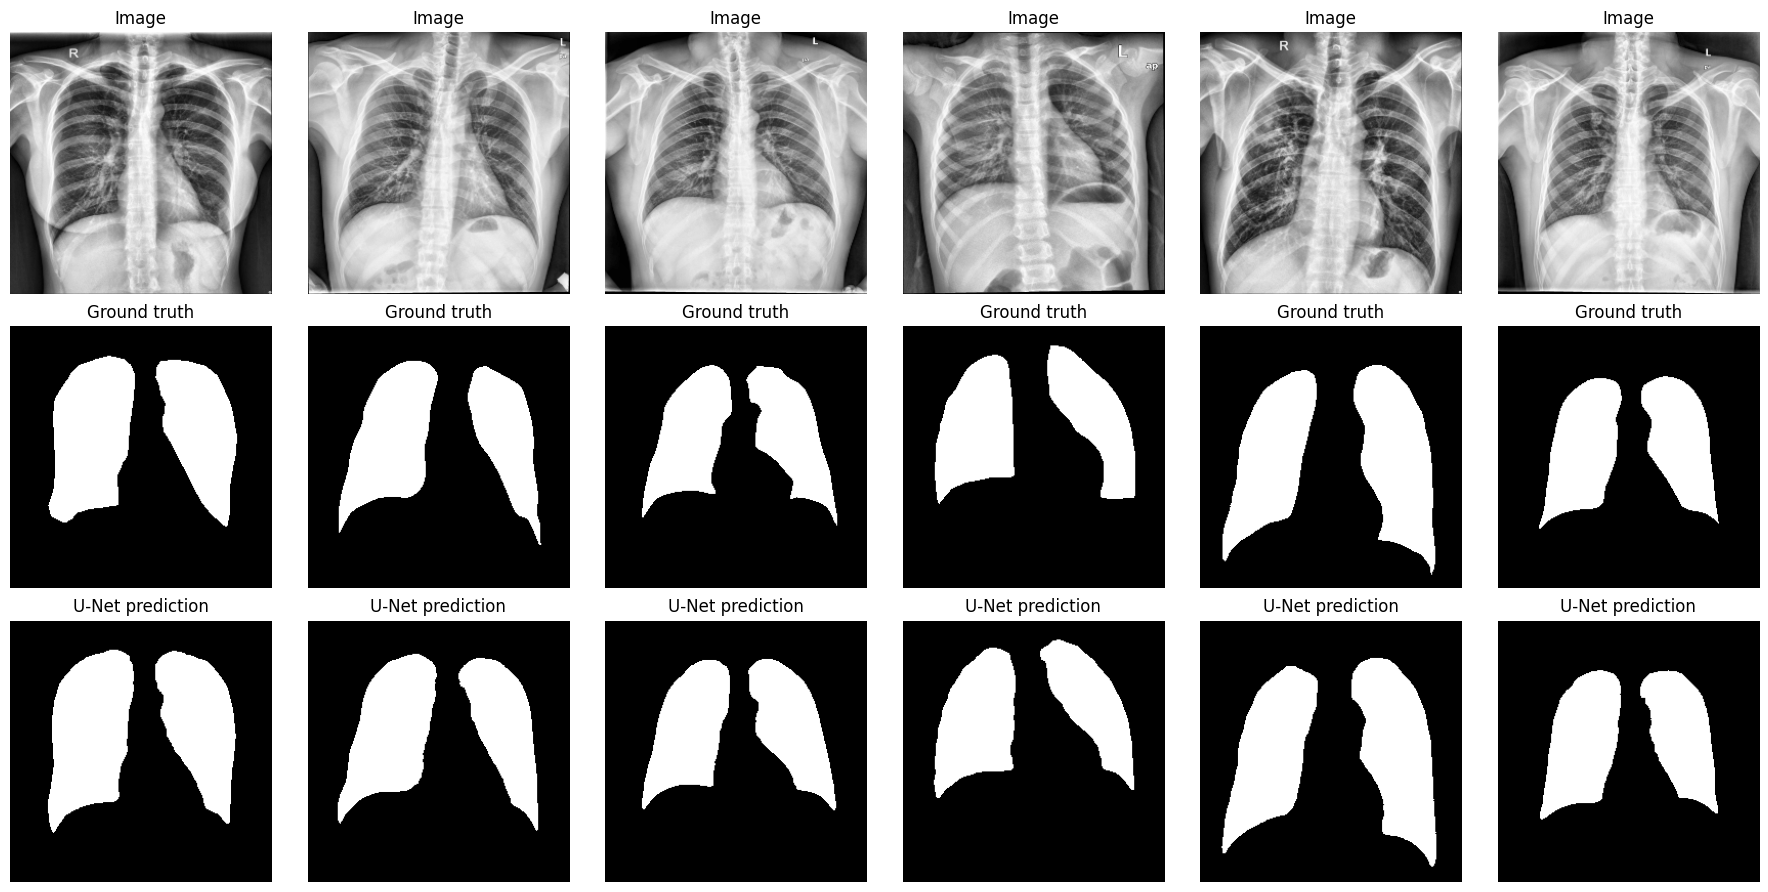

In [5]:
pred_va = unet.predict(Xva[:6], verbose=0)
fig, ax = plt.subplots(3, 6, figsize=(18, 9))
for i in range(6):
    ax[0, i].imshow(Xva[i, ..., 0], cmap='gray'); ax[0, i].set_title("Image")
    ax[1, i].imshow(Yva[i, ..., 0], cmap='gray'); ax[1, i].set_title("Ground truth")
    ax[2, i].imshow(pred_va[i, ..., 0] > 0.5, cmap='gray'); ax[2, i].set_title("U-Net prediction")
    for r in range(3): ax[r, i].axis('off')
plt.tight_layout(); plt.show()

label
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64


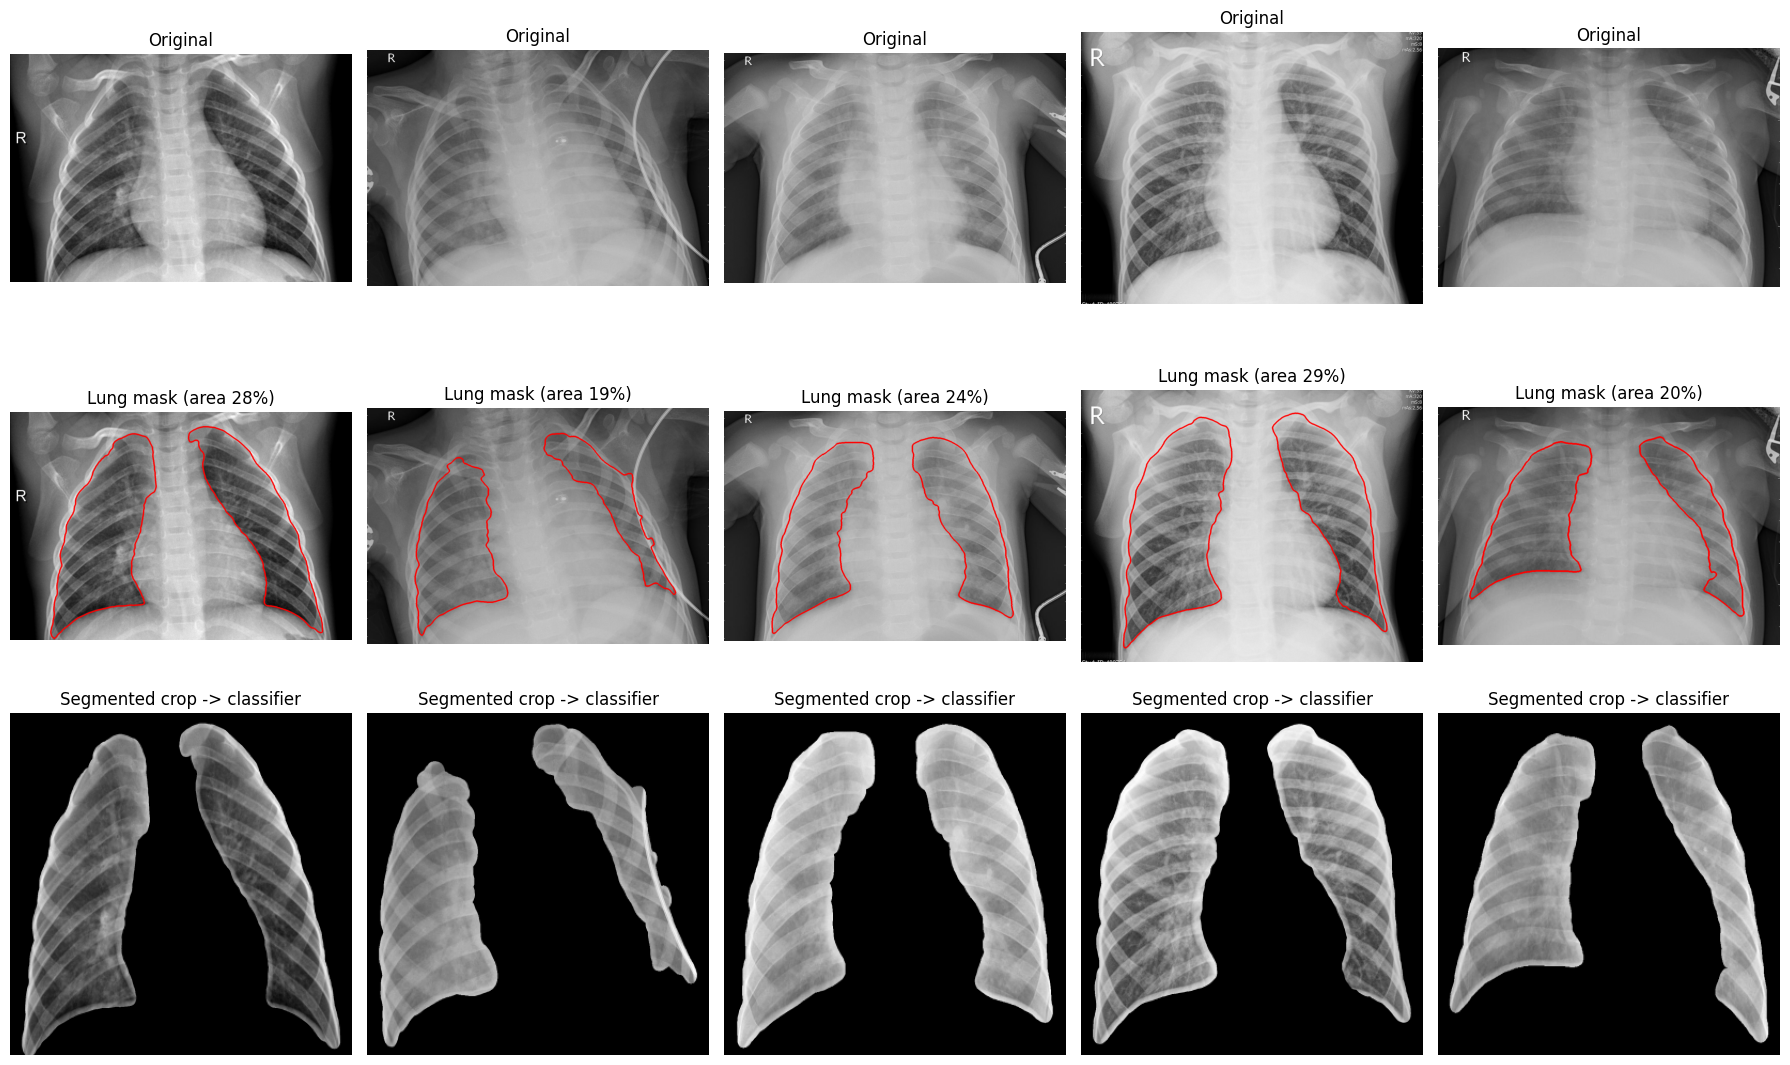

In [6]:
def _odd(k): return int(k) if int(k) % 2 == 1 else int(k) + 1

def clean_mask(m):
    """Close gaps, keep the 2 largest blobs (left/right lung), fill holes."""
    h, w = m.shape
    k = _odd(max(3, 0.02 * min(h, w)))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnts = [c for c in cnts if cv2.contourArea(c) >= 0.01 * h * w]
    cnts = sorted(cnts, key=cv2.contourArea, reverse=True)[:2]
    out = np.zeros_like(m)
    cv2.drawContours(out, cnts, -1, 1, thickness=-1)
    return out

def segment_from_prob(gray, prob):
    """gray: original uint8 image (H,W); prob: U-Net output (SEG_SIZE,SEG_SIZE)."""
    h, w = gray.shape
    m = (cv2.resize(prob.astype('float32'), (w, h), interpolation=cv2.INTER_LINEAR) > 0.5).astype('uint8')
    m = clean_mask(m)
    frac = float(m.mean())
    fallback = frac < MIN_LUNG_FRAC                       # segmentation failed -> use whole image
    if fallback:
        m = np.ones((h, w), dtype='uint8')
    k  = _odd(max(3, 0.03 * min(h, w)))                   # dilate so edge/costophrenic pathology is kept
    md_ = cv2.dilate(m, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    ys, xs = np.where(md_ > 0)
    my, mx = int(0.03 * h), int(0.03 * w)
    y0, y1 = max(ys.min() - my, 0), min(ys.max() + my + 1, h)
    x0, x1 = max(xs.min() - mx, 0), min(xs.max() + mx + 1, w)
    crop = (gray[y0:y1, x0:x1] * md_[y0:y1, x0:x1]).astype('uint8')
    crop = cv2.resize(crop, IMG_SIZE, interpolation=cv2.INTER_AREA)
    return dict(crop=crop, mask=m, mask_dil=md_, bbox=(x0, y0, x1, y1),
                fallback=fallback, lung_frac=frac, orig=gray)

def segment_image(path):
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    prob = unet.predict(seg_preprocess(gray)[None, ..., None], verbose=0)[0, ..., 0]
    return segment_from_prob(gray, prob)

# ---- pool all images (same as your original) ----
all_filepaths = glob.glob(f'{BASE_PATH}/*/*/*.jpeg')
labels = ['PNEUMONIA' if 'PNEUMONIA' in p else 'NORMAL' for p in all_filepaths]
df = pd.DataFrame({'filepath': all_filepaths, 'label': labels})
print(df['label'].value_counts())

# ---- visual check on random chest X-rays ----
sample = df.sample(5, random_state=1)['filepath'].tolist()
fig, ax = plt.subplots(3, 5, figsize=(18, 11))
for i, p in enumerate(sample):
    s = segment_image(p)
    overlay = cv2.cvtColor(s['orig'], cv2.COLOR_GRAY2RGB)
    cnts, _ = cv2.findContours(s['mask'], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(overlay, cnts, -1, (255, 0, 0), max(2, s['orig'].shape[0] // 200))
    ax[0, i].imshow(s['orig'], cmap='gray');  ax[0, i].set_title("Original")
    ax[1, i].imshow(overlay);                 ax[1, i].set_title(f"Lung mask (area {s['lung_frac']:.0%})")
    ax[2, i].imshow(s['crop'], cmap='gray');  ax[2, i].set_title("Segmented crop -> classifier")
    for r in range(3): ax[r, i].axis('off')
plt.tight_layout(); plt.show()

In [7]:
def segment_dataframe(frame, batch=64):
    out_paths, fallbacks, fracs = [], [], []
    for start in tqdm(range(0, len(frame), batch), desc="Segmenting"):
        chunk = frame['filepath'].iloc[start:start + batch].tolist()
        grays = [cv2.imread(p, cv2.IMREAD_GRAYSCALE) for p in chunk]
        probs = unet.predict(np.stack([seg_preprocess(g) for g in grays])[..., None], verbose=0)[..., 0]
        for j, (g, pr) in enumerate(zip(grays, probs)):
            s = segment_from_prob(g, pr)
            out = f'{SEG_OUT_DIR}/{start + j:05d}.jpg'
            cv2.imwrite(out, s['crop'], [cv2.IMWRITE_JPEG_QUALITY, 95])
            out_paths.append(out); fallbacks.append(s['fallback']); fracs.append(s['lung_frac'])
    return out_paths, fallbacks, fracs

df['seg_path'], df['seg_fallback'], df['lung_frac'] = segment_dataframe(df)
print(f"Fallback (segmentation failed -> full image): {df['seg_fallback'].sum()} / {len(df)}")

train_df, temp_df = train_test_split(df, test_size=0.20, stratify=df['label'], random_state=42)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=42)
print(f"Final Split -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

Segmenting:   0%|          | 0/92 [00:00<?, ?it/s]

Fallback (segmentation failed -> full image): 62 / 5856
Final Split -> Train: 4684, Val: 586, Test: 586


In [8]:
def apply_clahe(img):
    img = img.astype('uint8')
    if len(img.shape) == 3 and img.shape[2] == 3:
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        cl = clahe.apply(l)
        final_img = cv2.cvtColor(cv2.merge((cl, a, b)), cv2.COLOR_LAB2RGB)
    else:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        final_img = clahe.apply(img)
    return final_img.astype('float32') / 255.0

train_datagen = ImageDataGenerator(
    preprocessing_function=apply_clahe,
    rotation_range=10, zoom_range=0.1,
    width_shift_range=0.1, height_shift_range=0.1,
    horizontal_flip=True)
test_datagen = ImageDataGenerator(preprocessing_function=apply_clahe)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df, x_col='seg_path', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='binary', shuffle=True)
val_generator = test_datagen.flow_from_dataframe(
    dataframe=val_df, x_col='seg_path', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='binary', shuffle=False)
test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df, x_col='seg_path', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='binary', shuffle=False)

classes = train_generator.classes
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(classes), y=classes)
weight_dict = {0: class_weights[0], 1: class_weights[1]}
print("Class indices:", train_generator.class_indices, "| class weights:", weight_dict)

Found 4684 validated image filenames belonging to 2 classes.
Found 586 validated image filenames belonging to 2 classes.
Found 586 validated image filenames belonging to 2 classes.
Class indices: {'NORMAL': 0, 'PNEUMONIA': 1} | class weights: {0: np.float64(1.8499210110584519), 1: np.float64(0.6851960210649503)}


In [9]:
base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(1, activation='sigmoid')(x)
model = Model(inputs=base_model.input, outputs=predictions)

focal_loss = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=False, gamma=2.0)
METRICS = lambda: ['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]

print("\n--- Phase 1: Training Classification Head ---")
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss=focal_loss, metrics=METRICS())

checkpoint = ModelCheckpoint('best_densenet_model.keras', save_best_only=True, monitor='val_accuracy', mode='max')
early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

model.fit(train_generator, validation_data=val_generator, epochs=50,
          class_weight=weight_dict, callbacks=[checkpoint, early_stop])

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Phase 1: Training Classification Head ---
Epoch 1/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 183s 536ms/step - accuracy: 0.7047 - loss: 0.1625 - precision: 0.8731 - recall: 0.6966 - val_accuracy: 0.6775 - val_loss: 0.1483 - val_precision: 0.9722 - val_recall: 0.5738
Epoch 2/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 127s 434ms/step - accuracy: 0.7773 - loss: 0.1186 - precision: 0.9162 - recall: 0.7648 - val_accuracy: 0.8259 - val_loss: 0.0938 - val_precision: 0.9477 - val_recall: 0.8056
Epoch 3/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 124s 422ms/step - accuracy: 0.7980 - loss: 0.1088 - precision: 0.9250 - recall: 0.7870 - val_accuracy: 0.8396 - val_loss: 0.0887 - val_precision: 0.9612 - val_recall: 0.8126
Epoch 4/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 124s 424ms/step - accuracy: 0.8166 - loss: 0.1042 - precision: 0.9345 - recall: 0.8051 - val_accuracy: 0.8464 - val_loss: 0.0853 - val_precision: 0.9616 - val_recall: 0.8220
Epoch 5/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 117s 3

In [10]:
print("\n--- Phase 2: Unfreezing Top Block (conv5) ---")
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = 'conv5' in layer.name

phase2_epochs = 50
steps_per_epoch = len(train_generator)
lr_schedule_p2 = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4, decay_steps=phase2_epochs * steps_per_epoch, alpha=0.1)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule_p2), loss=focal_loss, metrics=METRICS())
model.fit(train_generator, validation_data=val_generator, epochs=phase2_epochs,
          class_weight=weight_dict, callbacks=[checkpoint, early_stop])


--- Phase 2: Unfreezing Top Block (conv5) ---
Epoch 1/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 248s 641ms/step - accuracy: 0.8416 - loss: 0.0952 - precision: 0.9425 - recall: 0.8338 - val_accuracy: 0.9010 - val_loss: 0.0469 - val_precision: 0.9578 - val_recall: 0.9040
Epoch 2/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 124s 422ms/step - accuracy: 0.9012 - loss: 0.0655 - precision: 0.9710 - recall: 0.8912 - val_accuracy: 0.9181 - val_loss: 0.0488 - val_precision: 0.9093 - val_recall: 0.9859
Epoch 3/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 128s 436ms/step - accuracy: 0.9172 - loss: 0.0538 - precision: 0.9746 - recall: 0.9102 - val_accuracy: 0.9113 - val_loss: 0.0551 - val_precision: 0.9947 - val_recall: 0.8829
Epoch 4/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 131s 448ms/step - accuracy: 0.9266 - loss: 0.0489 - precision: 0.9785 - recall: 0.9195 - val_accuracy: 0.9488 - val_loss: 0.0353 - val_precision: 0.9671 - val_recall: 0.9625
Epoch 5/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 128s 436ms/step - accuracy: 0.9306 - loss: 0.0466 - preci

In [11]:
print("\n--- Phase 3: Unfreezing Middle Block (conv4) ---")
for layer in base_model.layers:
    layer.trainable = ('conv4' in layer.name) or ('conv5' in layer.name)

phase3_epochs = 50
lr_schedule_p3 = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-5, decay_steps=phase3_epochs * steps_per_epoch, alpha=0.1)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule_p3), loss=focal_loss, metrics=METRICS())
model.fit(train_generator, validation_data=val_generator, epochs=phase3_epochs,
          class_weight=weight_dict, callbacks=[checkpoint, early_stop])


--- Phase 3: Unfreezing Middle Block (conv4) ---
Epoch 1/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 380s 849ms/step - accuracy: 0.9353 - loss: 0.0433 - precision: 0.9776 - recall: 0.9327 - val_accuracy: 0.9471 - val_loss: 0.0352 - val_precision: 0.9783 - val_recall: 0.9485
Epoch 2/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 133s 452ms/step - accuracy: 0.9436 - loss: 0.0358 - precision: 0.9837 - recall: 0.9383 - val_accuracy: 0.9522 - val_loss: 0.0327 - val_precision: 0.9716 - val_recall: 0.9625
Epoch 3/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 124s 423ms/step - accuracy: 0.9520 - loss: 0.0333 - precision: 0.9869 - recall: 0.9468 - val_accuracy: 0.9522 - val_loss: 0.0324 - val_precision: 0.9831 - val_recall: 0.9508
Epoch 4/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 124s 422ms/step - accuracy: 0.9530 - loss: 0.0314 - precision: 0.9860 - recall: 0.9491 - val_accuracy: 0.9505 - val_loss: 0.0331 - val_precision: 0.9830 - val_recall: 0.9485
Epoch 5/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 131s 446ms/step - accuracy: 0.9571 - loss: 0.0293 - pr

In [12]:
print("\n--- Evaluating Final Model on Test Data ---")
model = load_model('best_densenet_model.keras', compile=False)
model.compile(loss=focal_loss, metrics=METRICS())
test_loss, test_acc, test_prec, test_rec = model.evaluate(test_generator, verbose=0)
print(f"Final Test Accuracy:  {test_acc*100:.2f}%")
print(f"Final Test Precision: {test_prec*100:.2f}%")
print(f"Final Test Recall:    {test_rec*100:.2f}%")

y_true = test_generator.classes
y_prob_det = model.predict(test_generator, verbose=0).ravel()
y_pred_det = (y_prob_det >= 0.5).astype(int)
print("\nConfusion matrix [rows=true NORMAL/PNEUMONIA]:\n", confusion_matrix(y_true, y_pred_det))
print(classification_report(y_true, y_pred_det, target_names=['NORMAL', 'PNEUMONIA'], digits=4))


--- Evaluating Final Model on Test Data ---
Final Test Accuracy:  95.73%
Final Test Precision: 96.97%
Final Test Recall:    97.20%

Confusion matrix [rows=true NORMAL/PNEUMONIA]:
 [[145  13]
 [ 12 416]]
              precision    recall  f1-score   support

      NORMAL     0.9236    0.9177    0.9206       158
   PNEUMONIA     0.9697    0.9720    0.9708       428

    accuracy                         0.9573       586
   macro avg     0.9466    0.9448    0.9457       586
weighted avg     0.9573    0.9573    0.9573       586



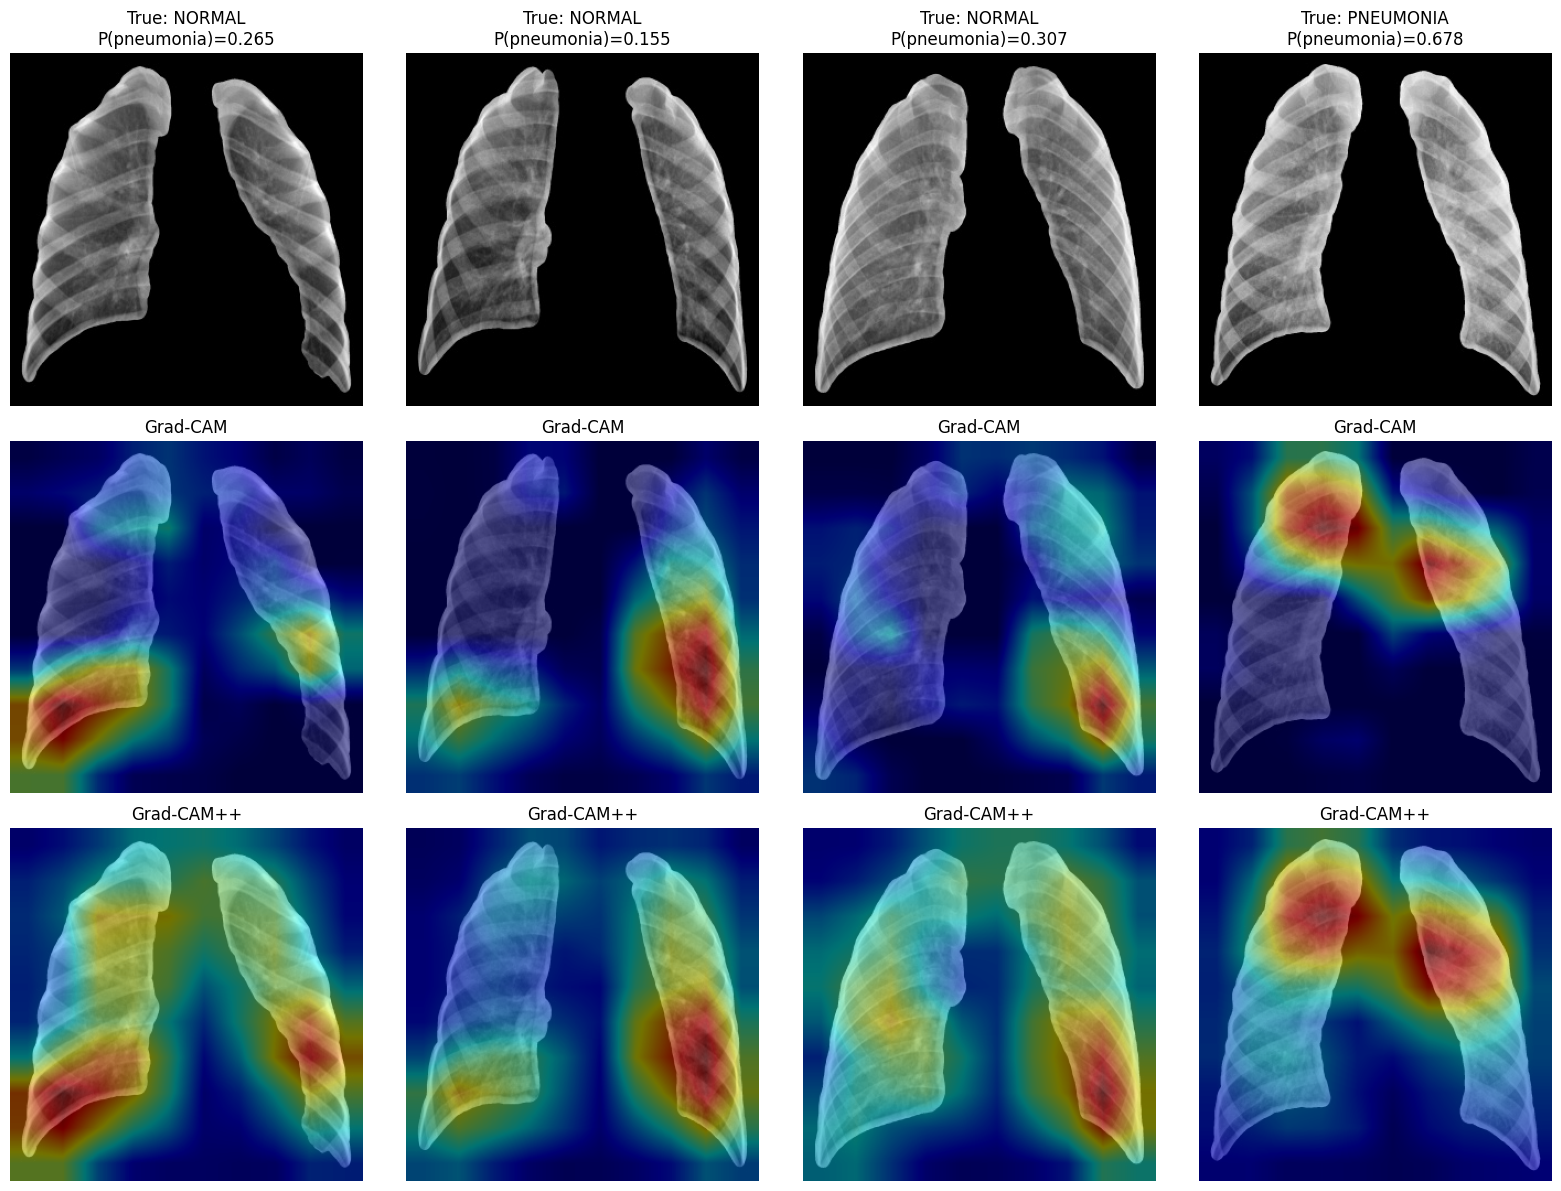

In [13]:
LAST_CONV = 'relu'   # final activation of DenseNet121 (10x10x1024 for 320x320 input)
gradcam_model = Model(model.inputs, [model.get_layer(LAST_CONV).output, model.output])

def _target_score(preds):
    """Score of the PREDICTED class: p if pneumonia, 1-p if normal."""
    p = preds[:, 0]
    return tf.where(p >= 0.5, p, 1.0 - p)

def make_gradcam(img_array):
    x = tf.convert_to_tensor(img_array)
    with tf.GradientTape() as tape:
        tape.watch(x)
        conv, preds = gradcam_model(x, training=False)
        score = _target_score(preds)
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2))                           # (B,K)
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0]
    return (cam / (tf.reduce_max(cam) + 1e-8)).numpy()

def make_gradcam_pp(img_array):
    """Grad-CAM++ (Chattopadhay et al., 2018) - closed form with exponential output."""
    x = tf.convert_to_tensor(img_array)
    with tf.GradientTape() as tape:
        tape.watch(x)
        conv, preds = gradcam_model(x, training=False)
        score = _target_score(preds)
    g1 = tape.gradient(score, conv)                                   # (1,h,w,K)
    g2, g3 = g1 ** 2, g1 ** 3
    sum_A = tf.reduce_sum(conv, axis=(1, 2), keepdims=True)           # (1,1,1,K)
    denom = 2.0 * g2 + sum_A * g3
    denom = tf.where(denom != 0.0, denom, tf.ones_like(denom))
    alpha = g2 / denom
    w = tf.reduce_sum(alpha * tf.nn.relu(g1), axis=(1, 2))            # (1,K)
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0]
    return (cam / (tf.reduce_max(cam) + 1e-8)).numpy()

def overlay_heatmap(gray_or_rgb, heatmap, alpha=0.45):
    img = gray_or_rgb if gray_or_rgb.ndim == 3 else cv2.cvtColor(gray_or_rgb, cv2.COLOR_GRAY2RGB)
    hm = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    hm = cv2.applyColorMap(np.uint8(255 * hm), cv2.COLORMAP_JET)[..., ::-1]
    return cv2.addWeighted(img, 1 - alpha, hm, alpha, 0)

def to_model_input(crop_gray):
    """320x320 gray crop -> network input (identical to the training pipeline)."""
    rgb = np.stack([crop_gray] * 3, axis=-1)
    return apply_clahe(rgb)[None].astype('float32')

# ---- Grad-CAM vs Grad-CAM++ on 4 test images ----
fig, ax = plt.subplots(3, 4, figsize=(16, 12))
for i in range(4):
    crop = cv2.imread(test_df['seg_path'].iloc[i], cv2.IMREAD_GRAYSCALE)
    xin = to_model_input(crop)
    p = float(model.predict(xin, verbose=0)[0, 0])
    ax[0, i].imshow(crop, cmap='gray'); ax[0, i].set_title(f"True: {test_df['label'].iloc[i]}\nP(pneumonia)={p:.3f}")
    ax[1, i].imshow(overlay_heatmap(crop, make_gradcam(xin)));    ax[1, i].set_title("Grad-CAM")
    ax[2, i].imshow(overlay_heatmap(crop, make_gradcam_pp(xin))); ax[2, i].set_title("Grad-CAM++")
    for r in range(3): ax[r, i].axis('off')
plt.tight_layout(); plt.show()

In [14]:
# Only the two Dropout layers in the head are made stochastic. The DenseNet backbone has no dropout
# and its BatchNorm layers must NOT run in training mode, so we cache the (deterministic) pooled
# features once and re-run only the dropout head T times - fast and statistically clean.
gap_layer   = next(l for l in model.layers if isinstance(l, GlobalAveragePooling2D))
feature_model = Model(model.input, gap_layer.output)
head_layers = model.layers[model.layers.index(gap_layer) + 1:]
print("MC head:", [type(l).__name__ for l in head_layers])

def mc_head(features, T):
    """features: (B,1024) -> (B,T) matrix of stochastic P(pneumonia)."""
    h = tf.repeat(tf.convert_to_tensor(features), T, axis=0)           # T copies per image
    for l in head_layers:
        h = l(h, training=True) if isinstance(l, Dropout) else l(h)
    return tf.reshape(h, (-1, T)).numpy()

def _H(p, eps=1e-7):                                                   # binary entropy in bits (0..1)
    return -(p * np.log2(p + eps) + (1 - p) * np.log2(1 - p + eps))

def uncertainty_stats(mc):
    p_mean = mc.mean(1)
    pred_entropy = _H(p_mean)                      # total uncertainty
    exp_entropy  = _H(mc).mean(1)                  # aleatoric part
    return dict(p_mean=p_mean, p_std=mc.std(1), entropy=pred_entropy,
                mutual_info=pred_entropy - exp_entropy)   # epistemic part

# ---- run over the whole test set ----
feats = feature_model.predict(test_generator, verbose=1)
mc_all = np.vstack([mc_head(feats[i:i + 64], T_MC) for i in range(0, len(feats), 64)])
u = uncertainty_stats(mc_all)

y_true = test_generator.classes
y_pred = (u['p_mean'] >= 0.5).astype(int)
correct = (y_pred == y_true)
flag = u['entropy'] > ENTROPY_THRESH

print(f"\nMC-Dropout accuracy (T={T_MC}): {correct.mean()*100:.2f}%")
print(f"Flagged for review (entropy > {ENTROPY_THRESH}): {flag.sum()} / {len(flag)} ({flag.mean()*100:.1f}%)")
print(f"  error rate among flagged   : {(~correct[flag]).mean()*100 if flag.any() else float('nan'):.2f}%")
print(f"  error rate among unflagged : {(~correct[~flag]).mean()*100:.2f}%")
print(f"Mean std  | correct: {u['p_std'][correct].mean():.4f}  wrong: {u['p_std'][~correct].mean() if (~correct).any() else float('nan'):.4f}")
print("\nConfusion matrix (MC mean):\n", confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=['NORMAL', 'PNEUMONIA'], digits=4))

MC head: ['Dropout', 'Dense', 'Dropout', 'Dense']
37/37 ━━━━━━━━━━━━━━━━━━━━ 27s 430ms/step

MC-Dropout accuracy (T=30): 95.56%
Flagged for review (entropy > 0.5): 121 / 586 (20.6%)
  error rate among flagged   : 19.83%
  error rate among unflagged : 0.43%
Mean std  | correct: 0.0235  wrong: 0.0872

Confusion matrix (MC mean):
 [[144  14]
 [ 12 416]]
              precision    recall  f1-score   support

      NORMAL     0.9231    0.9114    0.9172       158
   PNEUMONIA     0.9674    0.9720    0.9697       428

    accuracy                         0.9556       586
   macro avg     0.9453    0.9417    0.9434       586
weighted avg     0.9555    0.9556    0.9555       586



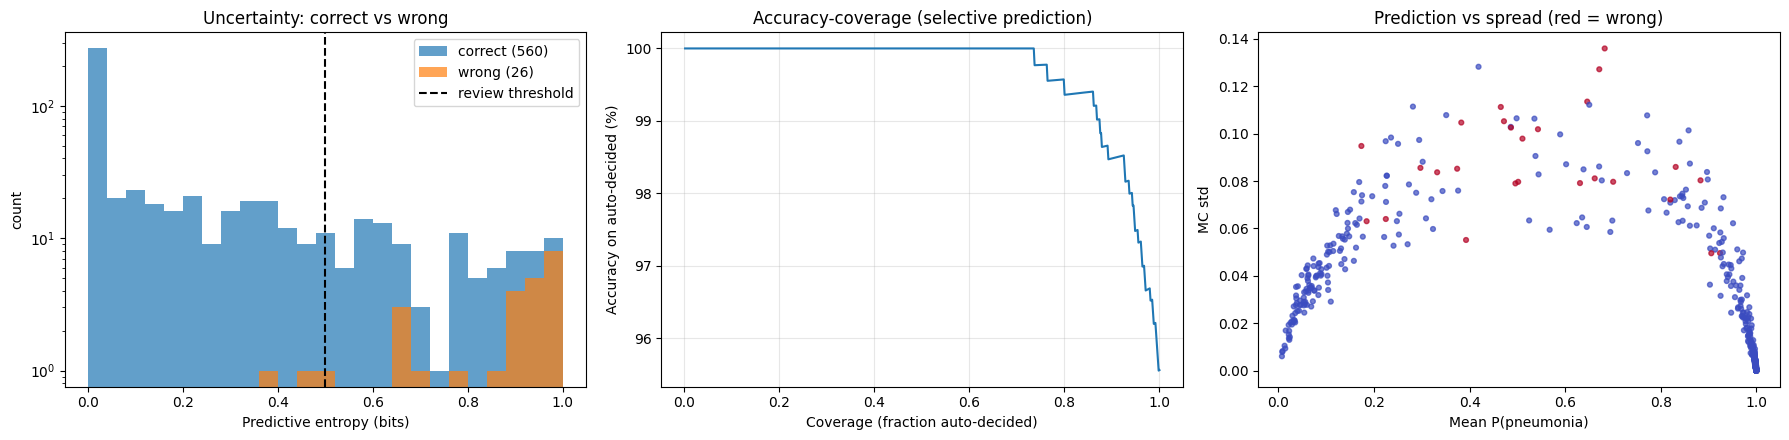

Pick ENTROPY_THRESH from this table (accuracy vs. how many cases go to a clinician):


,entropy_thresh,coverage,accuracy_on_kept,referred_to_expert,errors_caught,total_errors
0,0.1,52.0%,100.00%,281,26,26
1,0.2,59.7%,100.00%,236,26,26
2,0.3,66.0%,100.00%,199,26,26
3,0.4,74.2%,99.77%,151,25,26
4,0.5,79.4%,99.57%,121,24,26
5,0.6,83.4%,99.39%,97,23,26
6,0.7,88.1%,98.64%,70,19,26
7,0.8,90.6%,98.49%,55,18,26


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

bins = np.linspace(0, 1, 26)
ax[0].hist(u['entropy'][correct], bins=bins, alpha=0.7, label=f'correct ({correct.sum()})')
if (~correct).any():
    ax[0].hist(u['entropy'][~correct], bins=bins, alpha=0.7, label=f'wrong ({(~correct).sum()})')
ax[0].axvline(ENTROPY_THRESH, color='k', ls='--', label='review threshold')
ax[0].set_yscale('log'); ax[0].set_xlabel('Predictive entropy (bits)'); ax[0].set_ylabel('count'); ax[0].legend()
ax[0].set_title('Uncertainty: correct vs wrong')

order = np.argsort(u['entropy'])                       # most certain first
cov = np.arange(1, len(order) + 1) / len(order)
acc_at_cov = np.cumsum(correct[order]) / np.arange(1, len(order) + 1)
ax[1].plot(cov, acc_at_cov * 100)
ax[1].set_xlabel('Coverage (fraction auto-decided)'); ax[1].set_ylabel('Accuracy on auto-decided (%)')
ax[1].set_title('Accuracy-coverage (selective prediction)'); ax[1].grid(alpha=0.3)

sc = ax[2].scatter(u['p_mean'], u['p_std'], c=correct, cmap='coolwarm_r', s=12, alpha=0.7)
ax[2].set_xlabel('Mean P(pneumonia)'); ax[2].set_ylabel('MC std'); ax[2].set_title('Prediction vs spread (red = wrong)')
plt.tight_layout(); plt.show()

rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    keep = u['entropy'] <= t
    rows.append(dict(entropy_thresh=t, coverage=f"{keep.mean()*100:.1f}%",
                     accuracy_on_kept=f"{correct[keep].mean()*100:.2f}%" if keep.any() else "-",
                     referred_to_expert=int((~keep).sum()),
                     errors_caught=int((~correct[~keep]).sum()), total_errors=int((~correct).sum())))
print("Pick ENTROPY_THRESH from this table (accuracy vs. how many cases go to a clinician):")
display(pd.DataFrame(rows))

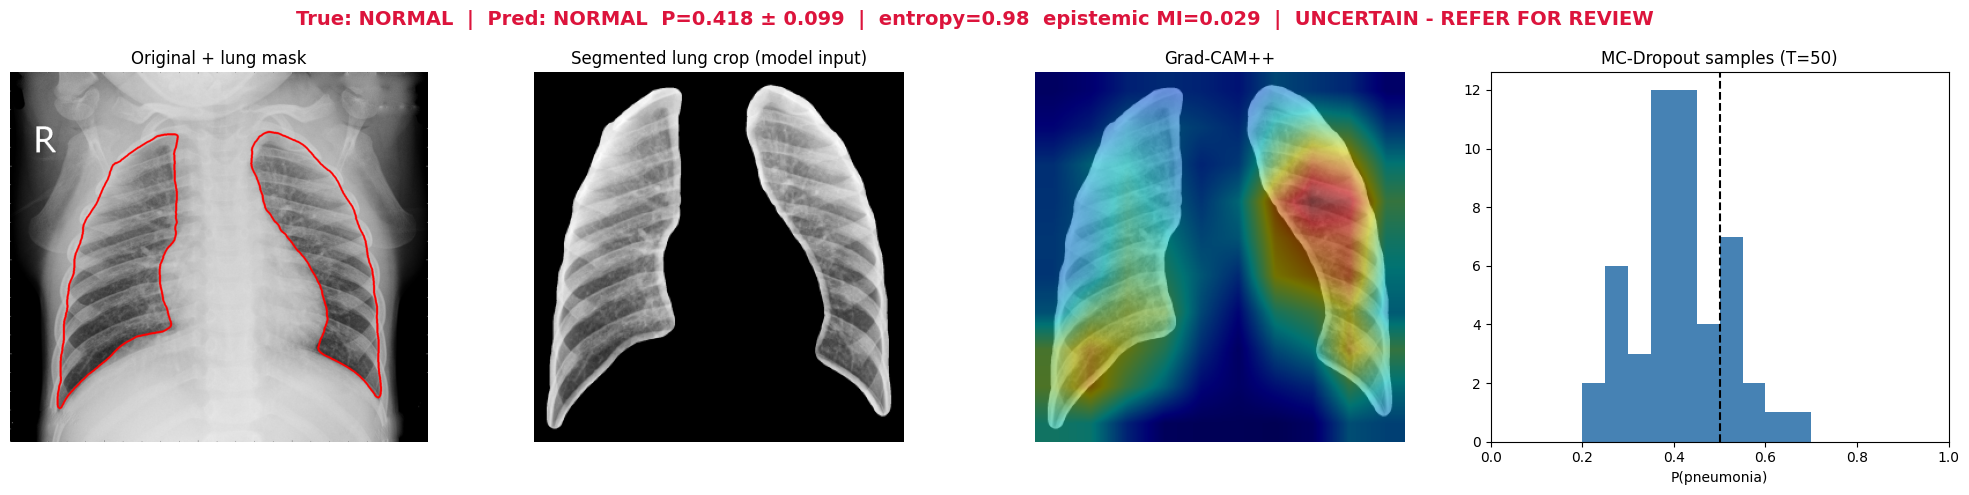

{'label': 'NORMAL', 'prob': 0.4178740680217743, 'std': 0.09879211336374283, 'entropy': 0.9804502725601196, 'mutual_info': 0.029420554637908936, 'needs_review': True, 'segmentation_fallback': False}


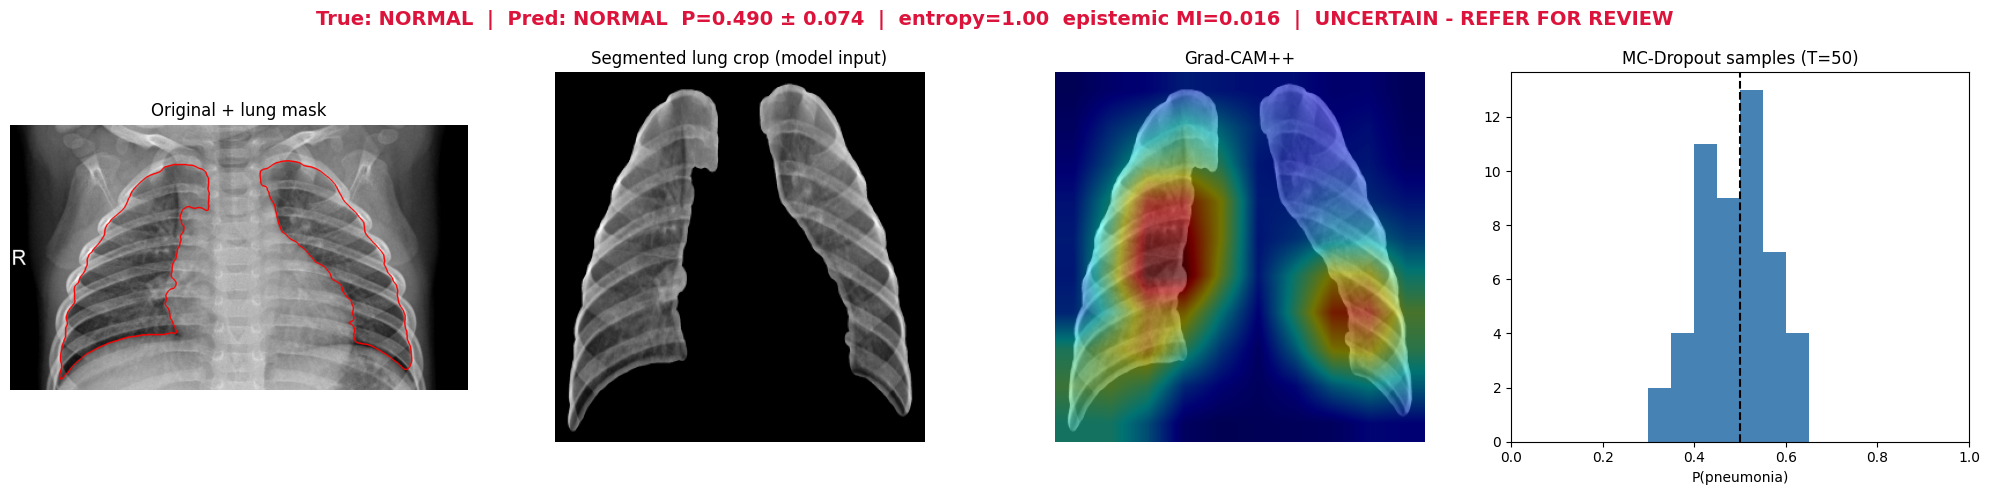

{'label': 'NORMAL', 'prob': 0.4895569682121277, 'std': 0.07404214888811111, 'entropy': 0.9996850490570068, 'mutual_info': 0.01598876714706421, 'needs_review': True, 'segmentation_fallback': False}


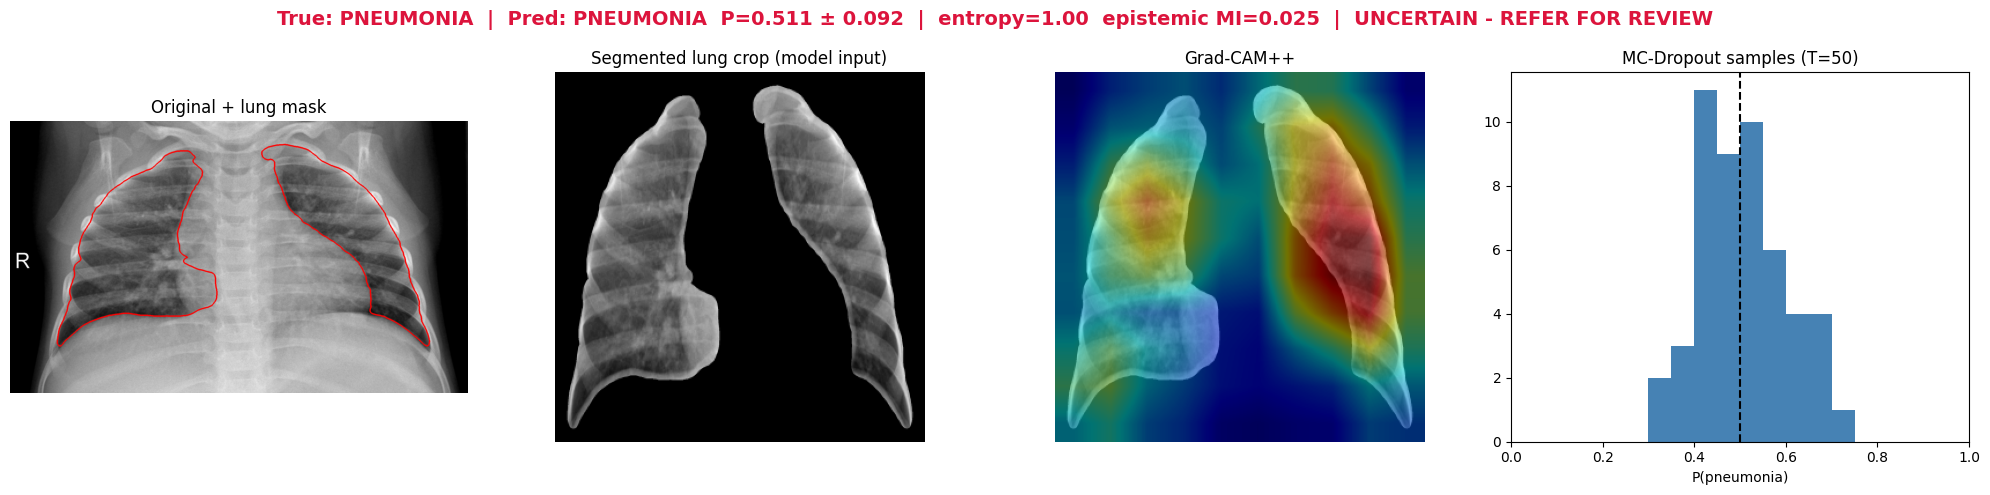

{'label': 'PNEUMONIA', 'prob': 0.5107632875442505, 'std': 0.09212272614240646, 'entropy': 0.9996654391288757, 'mutual_info': 0.02485138177871704, 'needs_review': True, 'segmentation_fallback': False}


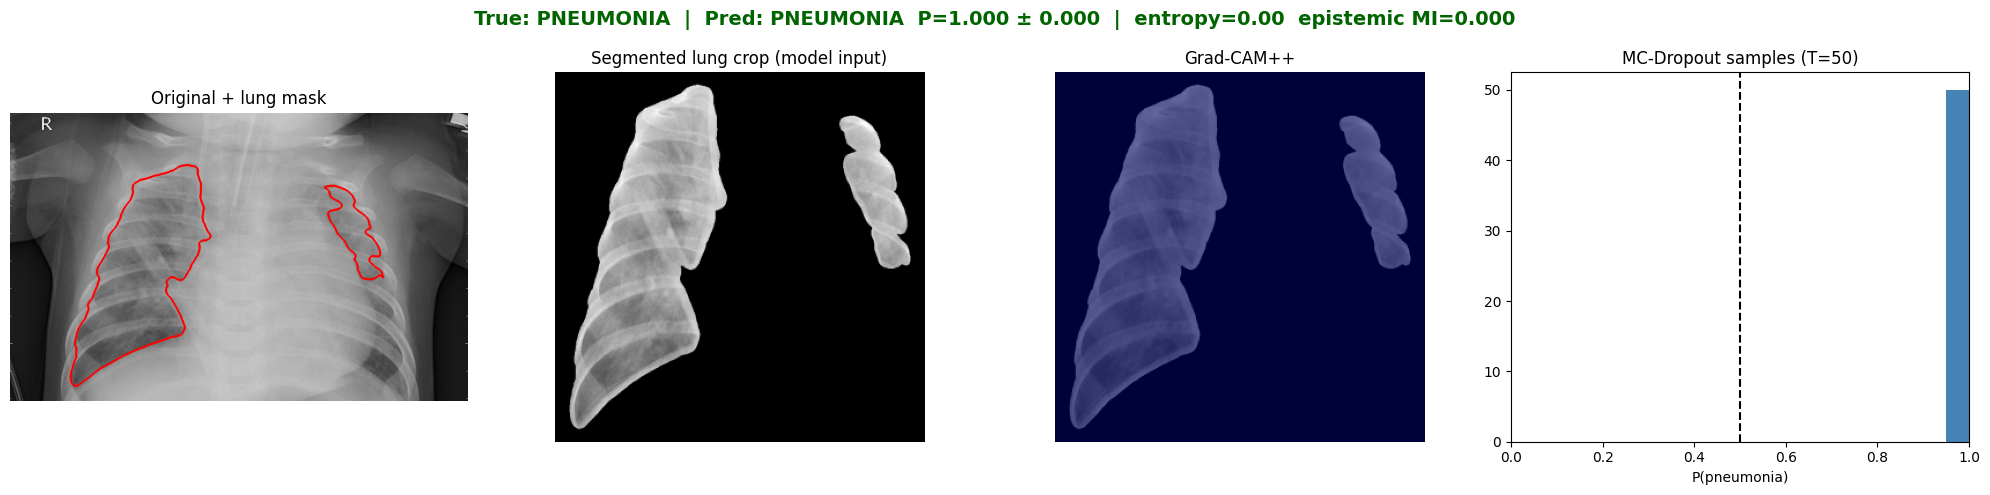

{'label': 'PNEUMONIA', 'prob': 0.9999997615814209, 'std': 1.3634750075652846e-06, 'entropy': 5.29671569893253e-06, 'mutual_info': 1.0724261301220395e-07, 'needs_review': False, 'segmentation_fallback': False}


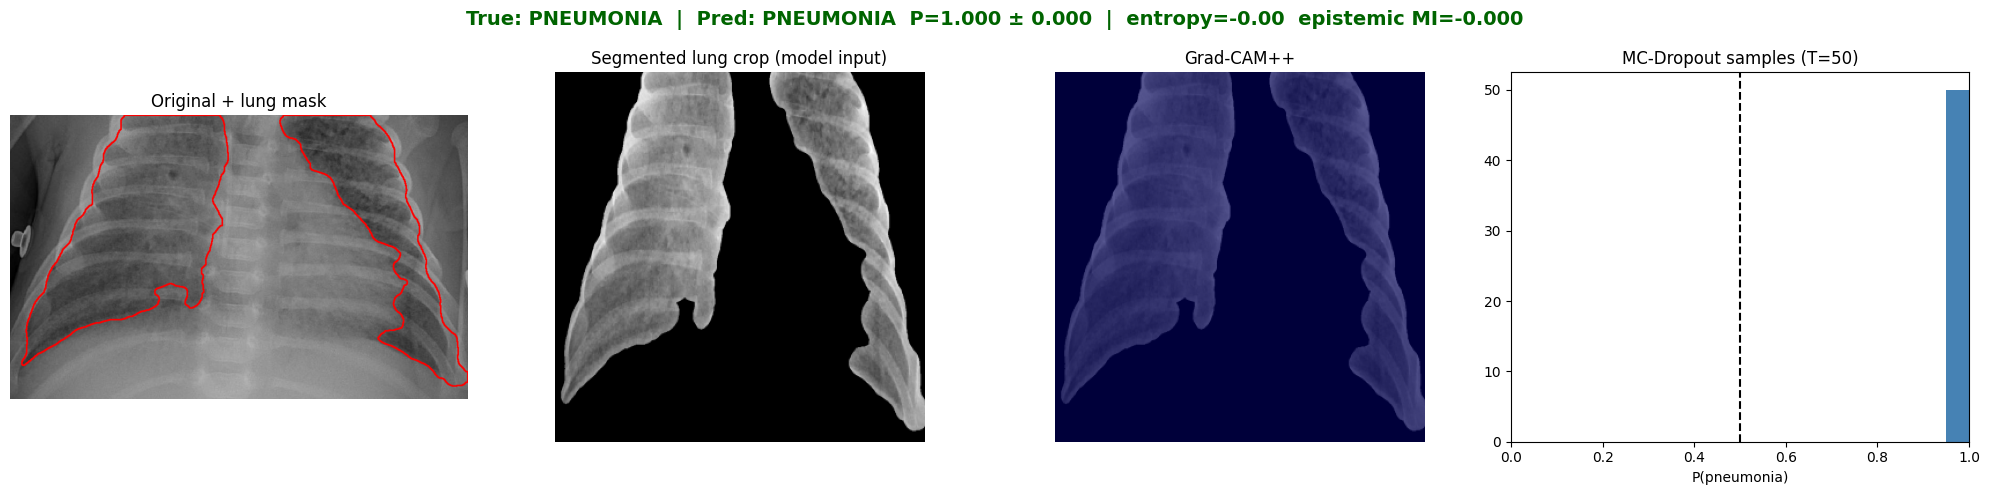

{'label': 'PNEUMONIA', 'prob': 1.0, 'std': 2.528810796320613e-07, 'entropy': -1.7198263435602712e-07, 'mutual_info': -7.316100436582929e-07, 'needs_review': False, 'segmentation_fallback': False}


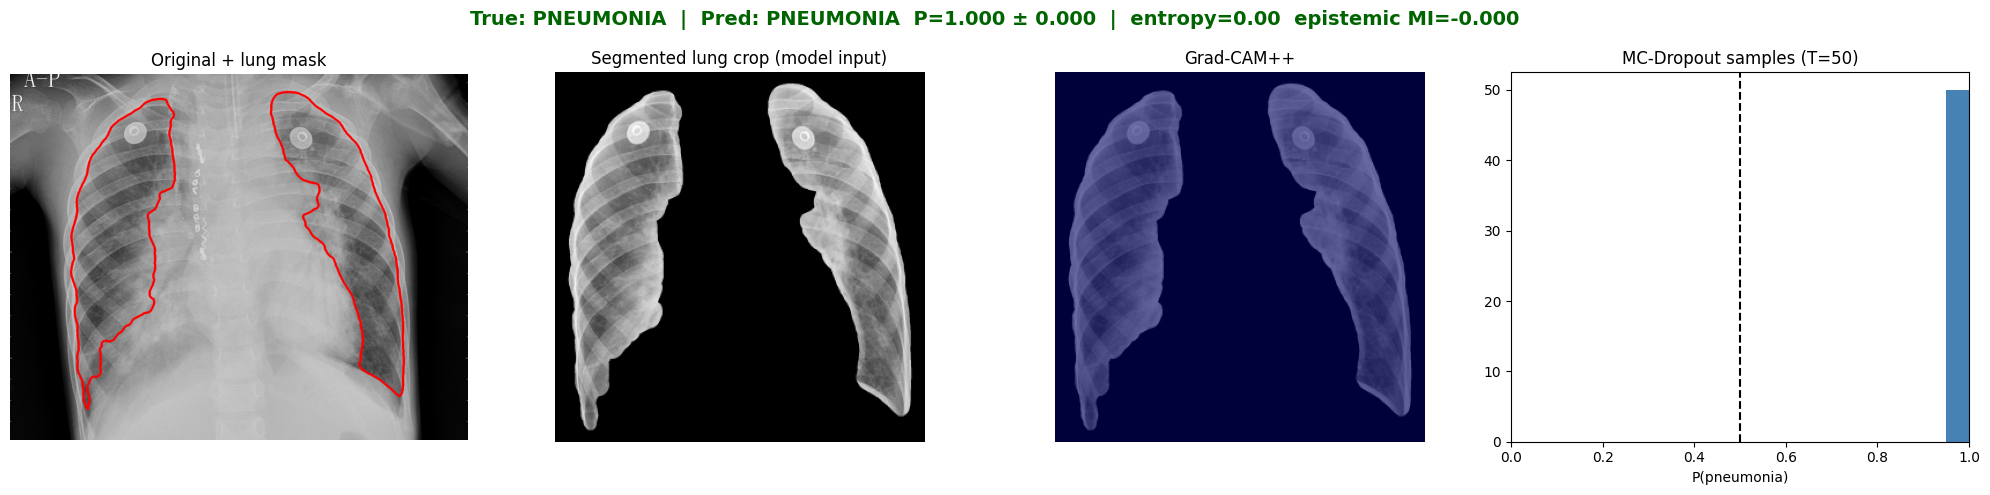

{'label': 'PNEUMONIA', 'prob': 0.9999997019767761, 'std': 1.0750668479886372e-06, 'entropy': 6.594139904336771e-06, 'mutual_info': -8.806737241684459e-07, 'needs_review': False, 'segmentation_fallback': False}


In [16]:
def analyze_xray(path, T=T_INFER, entropy_thresh=ENTROPY_THRESH, true_label=None):
    seg = segment_image(path)                                            # 1) lung segmentation
    xin = to_model_input(seg['crop'])
    feats_1 = feature_model(xin, training=False)
    mc = mc_head(feats_1, T)                                             # 2) MC Dropout (1,T)
    st = uncertainty_stats(mc)
    p, sd, ent, mi = st['p_mean'][0], st['p_std'][0], st['entropy'][0], st['mutual_info'][0]
    label = 'PNEUMONIA' if p >= 0.5 else 'NORMAL'
    needs_review = bool(ent > entropy_thresh)
    cam = make_gradcam_pp(xin)                                           # 3) Grad-CAM++

    outline = cv2.cvtColor(seg['orig'], cv2.COLOR_GRAY2RGB)
    cnts, _ = cv2.findContours(seg['mask'], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(outline, cnts, -1, (255, 0, 0), max(2, seg['orig'].shape[0] // 200))

    fig, ax = plt.subplots(1, 4, figsize=(20, 5))
    ax[0].imshow(outline); ax[0].set_title("Original + lung mask")
    ax[1].imshow(seg['crop'], cmap='gray'); ax[1].set_title("Segmented lung crop (model input)")
    ax[2].imshow(overlay_heatmap(seg['crop'], cam)); ax[2].set_title("Grad-CAM++")
    ax[3].hist(mc[0], bins=np.linspace(0, 1, 21), color='steelblue')
    ax[3].axvline(0.5, color='k', ls='--'); ax[3].set_xlim(0, 1)
    ax[3].set_title(f"MC-Dropout samples (T={T})"); ax[3].set_xlabel("P(pneumonia)")
    for a in ax[:3]: a.axis('off')
    tag = "  |  UNCERTAIN - REFER FOR REVIEW" if needs_review else ""
    gt = f"True: {true_label}  |  " if true_label else ""
    fig.suptitle(f"{gt}Pred: {label}  P={p:.3f} ± {sd:.3f}  |  entropy={ent:.2f}  epistemic MI={mi:.3f}{tag}",
                 fontsize=14, fontweight='bold', color='crimson' if needs_review else 'darkgreen')
    plt.tight_layout(); plt.show()
    return dict(label=label, prob=float(p), std=float(sd), entropy=float(ent),
                mutual_info=float(mi), needs_review=needs_review, segmentation_fallback=seg['fallback'])

# ---- demo: 3 most uncertain test cases + 3 confident correct ones (full pipeline from RAW images) ----
uncertain_idx = np.argsort(-u['entropy'])[:3]
confident_idx = [i for i in np.argsort(u['entropy']) if correct[i]][:3]
for i in list(uncertain_idx) + list(confident_idx):
    row = test_df.iloc[i]
    print(analyze_xray(row['filepath'], true_label=row['label']))

In [17]:
model.save("/kaggle/working/best_densenet_model.keras")
unet.save("/kaggle/working/unet_lung_model.keras")     # reload with custom_objects={'bce_dice_loss':..., 'dice_coef':...}
unet.save_weights("/kaggle/working/unet_lung.weights.h5")
df.to_csv("/kaggle/working/dataset_with_segmentation.csv", index=False)
print(os.listdir('/kaggle/working'))

['best_densenet_model.keras', 'seg_images', 'unet_lung_model.keras', 'dataset_with_segmentation.csv', '__notebook__.ipynb', 'unet_lung.weights.h5']
